### 1. Exploratory Data Analysis

#### Objectif :
La date index correspond au point d’entrée du patient dans l’étude (début du suivi ou du traitement).
    - La période pré-index décrit l’état clinique, les comorbidités et l’utilisation des soins avant cette date.
    - La période post-index permet d’évaluer l’évolution du patient après cette date, ici à travers la survenue d’exacerbations.
> Objectif : comprendre les données avant de modéliser pour proposer une strategie (type , imputation , Modèles tolérant les manquants )

#### Description variables :

- En général, **pré-index** fait référence à l'activité ou aux caractéristiques du patient qui existaient avant qu'il ne soit assigné à l'un des groupes de traitement. **Post-index** fait référence aux mesures d'activité après l'attribution du traitement. Dans ce cas, la mesure post-index correspond au nombre d'exacerbations durant la première année après le début de l'étude.

- Une **exacerbation** correspond à une aggravation aiguë ou subaiguë des symptômes de l’asthme, nécessitant une intervention médicale supplémentaire par rapport au traitement habituel. **Nombre d’exacerbations durant les 12 mois suivant la date index**

#### Checklist de base
#### Analyse de la structure :
- **variable target** : post_index_exacerbations365
- **lignes et colonnes** : 14575, 21
- **Type** : 52.4% int8 (binaire) , 19% int64 , 28.6% float 64

#### Analyse des variables :
    
- **Univariés** :
    -  **Age** : Distribution étalée entre ~10 et 65 ans, avec deux zones de concentration : adolescence et quarantaine/cinquantaine ; la distribution n’est pas parfaitement symétrique.
    - **total_pre_index_cannisters_365 (SABA)** : Distribution très concentrée sur les faibles valeurs (0–1 bonbonne), avec peu de patients à 2 bonbonnes ; légère asymétrie à droite.
    - **pre_asthma_days** : Forte concentration sur 0 et 1–5 jours de traitement ; les valeurs supérieures à 5 jours sont rares ; distribution très asymétrique à droite.
    - **pre_asthma_charge (non‑pharma)** : Distribution très asymétrique avec une majorité de faibles montants et quelques valeurs très élevées ; présence de nombreux outliers.
    - **pre_asthma_pharma_charge (pharma)** : Profil similaire aux charges non-pharma : majorité de faibles coûts et quelques montants extrêmes ; asymétrie marquée à droite.
    - **total_pre_index_charge** : Distribution fortement asymétrique avec une concentration de petits montants et quelques valeurs très élevées
    - **log_charges** : Après transformation logarithmique, distribution plus symétrique et proche d’une forme quasi normale.
    - **log_asthma_charge** : Distribution plus équilibrée après transformation, avec une dispersion modérée et moins d’effet des valeurs extrêmes.
    - **female** : 
    - **post_index_exacerbations365** : Variable binaire déséquilibrée, avec environ 82,5 % de non-survenue contre 17,5 % de survenue.
    


- **Bivariés : Relation Target/Variables** :
    - target / Age : La tranche 40–49 ans contient le plus grand nombre total de patients.
    - target / sexe : Les femmes présentent un taux d’exacerbation legerement plus élevé que les hommes.
    - target/coûts : les patients ayant eu une exacerbation semblent présenter des coûts pré-index un peu plus élevés, surtout en coûts totaux, mais les distributions restent fortement chevauchées entre les deux groupes.
    - target/comorbidités : Aucune comorbidité ne montre une différence visuellement très marquée par rapport aux autres.
    - target / Intensité de la prise en charge et utilisation traitement : Le nombre de jours de traitement pré-index est fortement concentré entre 0 et 5 jours dans les deux groupes, avec des profils très proches, quelques valeurs extrêmes surtout chez les non-exacerbés, et sans tendance progressive des exacerbations lorsque le nombre de jours augmente.
    - target / drug_s
    - target / aderance 

    
## Analyse plus détaillée

- **Relation Variables / Variables** :
    - charge / charge : certaines variables sont tres corrélées 
    - charge / age : l’âge est légèrement corrélé (une association positive faible) aux coûts globaux (version logarithmique)
    - charge / traitement : influenza rapid test donne de mauvais résultats, il fauda peut-etre la laisser tomber
    - relation comorbidité / blood data : Les taux sanguins entre malades et covid-19 sont différents
    - relation hospitalisation / est malade : 
    - relation hospitalisation / blood : intéressant dans le cas ou on voudrait prédire dans quelle service un patient devrait aller


- **NaN analyse** : viral : 1350(92/8), blood : 600(87/13), both : 90

### hypotheses nulle (H0): 

- Les individus atteints du covid-19 ont des taux de Leukocytes, Monocytes, Platelets significativement différents
    - H0 = Les taux moyens sont ÉGAUX chez les individus positifs et négatifs

- Les individus atteints d'une quelconque maladie ont des taux significativement différents


    

In [50]:
# Importation des bibliotheques 
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import polars.selectors as cs
import seaborn as sns
from scipy import stats

In [51]:
pl.Config.set_tbl_cols(-1) # afficher toute les colonnes 
pl.Config.set_tbl_rows(-1) # afficher toute les lignes

polars.config.Config

In [52]:
pd.set_option('display.max_row',19)
pd.set_option('display.max_columns',19)

### **Structure**

In [53]:
df=pl.read_csv(r"C:\Users\Abdo\OneDrive\Desktop\3. M1\Data Challenge 2\notebook\Data\trainDataDC2.csv.gz")
# Aperçu 3 enregistrements àleatoire 
df.sample(n=5)

patid,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,post_index_exacerbations365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
i64,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
1492081659,"""NA""","""1""","""0""",0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0.0326975477""","""2130.263531""","""0""","""0""","""12.1""","""1""","""1""","""7.6640009745""","""2.4932054526"""
1251108971,"""37""","""NA""","""1""",0,"""1""","""1""","""0""","""0""","""0""","""0""","""0""","""NA""","""3777.8355039""","""0""","""0""","""23.96""","""0""","""0""","""8.2369065066""","""3.1763857732"""
1124861288,"""42""","""1""","""0""",0,"""NA""","""0""","""0""","""0""","""0""","""0""","""NA""","""0.8991825613""","""4577.7124403""","""0""","""NA""","""10.65""","""0""","""0""","""8.4289546852""","""2.3655598922"""
1594761974,"""44""","""1""","""NA""",0,"""0""","""NA""","""0""","""0""","""NA""","""0""","""1""","""0.0844686649""","""1633.4202779""","""1""","""62""","""39.4""","""0""","""1""","""7.3984314254""","""3.6737658163"""
1321300757,"""34""","""1""","""1""",0,"""0""","""0""","""0""","""0""","""1""","""0""","""0""","""0.0844686649""","""23845.874961""","""2""","""2244""","""41.43""","""0""","""1""","""10.079366524""","""3.7240052561"""


In [5]:
df.shape

(14575, 21)

In [6]:
# Doublons par identifiant
df.group_by("patid").count().filter(pl.col("count") > 1)
# Aucun doublons 

C:\Users\Abdo\AppData\Local\Temp\ipykernel_11088\916252613.py:2: DeprecationWarning: `GroupBy.count` was renamed; use `GroupBy.len` instead
  df.group_by("patid").count().filter(pl.col("count") > 1)


patid,count
i64,u32


In [7]:
df.schema

Schema([('patid', Int64),
        ('index_age', String),
        ('previous_asthma_drugs', String),
        ('total_pre_index_cannisters_365', String),
        ('post_index_exacerbations365', Int64),
        ('pneumonia', String),
        ('sinusitis', String),
        ('acute_bronchitis', String),
        ('acute_laryngitis', String),
        ('upper_respiratory_infection', String),
        ('gerd', String),
        ('rhinitis', String),
        ('adherence', String),
        ('total_pre_index_charge', String),
        ('pre_asthma_days', String),
        ('pre_asthma_charge', String),
        ('pre_asthma_pharma_charge', String),
        ('drug_s', String),
        ('female', String),
        ('log_charges', String),
        ('log_asthma_charge', String)])

In [ ]:
df.glimpse()
# affiche :
#le nombre de lignes
# le nombre de colonnes
# le nom et le type de chaque variable
# les valeurs exemples de chaque colonne

Rows: 14575
Columns: 21
$ patid                          <i64> 1073754155, 1073799394, 1073854918, 1073898249, 1073913003, 1073928980, 1074030062, 1074078078, 1074166886, 1074184402
$ index_age                      <str> '14', 'NA', '62', 'NA', '40', '64', '37', '62', '18', 'NA'
$ previous_asthma_drugs          <str> '1', '1', '1', '1', '1', '1', 'NA', '1', '1', '1'
$ total_pre_index_cannisters_365 <str> '1', '2', 'NA', '2', '1', '1', '0', '1', '1', '2'
$ post_index_exacerbations365    <i64> 0, 2, 0, 0, 0, 0, 0, 0, 0, 0
$ pneumonia                      <str> '0', '0', '0', '0', '0', '0', '0', '0', '0', '0'
$ sinusitis                      <str> '0', '1', '0', '0', '1', '0', '0', '0', 'NA', '0'
$ acute_bronchitis               <str> '1', '1', 'NA', '1', '0', '1', '1', '0', '0', '1'
$ acute_laryngitis               <str> '0', '0', '0', '0', '1', '0', '0', '0', '0', '0'
$ upper_respiratory_infection    <str> '1', '0', '0', '1', '1', '1', '0', '1', '0', '0'
$ gerd                          

: 

In [9]:
int_cols = [
        "index_age",
        "total_pre_index_cannisters_365",
        "pre_asthma_days"
    ]
    
float_cols = [
    "total_pre_index_charge", #total_pre_index_charge et pre_asthma_charge sont les coûts réels (échelle brute)
    "pre_asthma_charge",
    "pre_asthma_pharma_charge",
    "log_charges", # log_charges et log_asthma_charge sont ces mêmes coûts après transformation log.
    "log_asthma_charge",
    "adherence",
]

binary_cols = [
    "previous_asthma_drugs", "pneumonia", "sinusitis",
    "acute_bronchitis", "acute_laryngitis",
    "upper_respiratory_infection", "gerd",
    "rhinitis", "drug_s", "female","post_index_exacerbations365"
]

In [10]:
# caster les colonnes vers les bons types

def cast_columns(df: pl.DataFrame) -> pl.DataFrame:
    
    return df.with_columns(
        pl.col(int_cols).cast(pl.Int64, strict=False),
        pl.col(float_cols).cast(pl.Float64, strict=False),
        pl.col(binary_cols).cast(pl.Int8, strict=False)
    )
df = cast_columns(df)


In [11]:
df.schema

Schema([('patid', Int64),
        ('index_age', Int64),
        ('previous_asthma_drugs', Int8),
        ('total_pre_index_cannisters_365', Int64),
        ('post_index_exacerbations365', Int8),
        ('pneumonia', Int8),
        ('sinusitis', Int8),
        ('acute_bronchitis', Int8),
        ('acute_laryngitis', Int8),
        ('upper_respiratory_infection', Int8),
        ('gerd', Int8),
        ('rhinitis', Int8),
        ('adherence', Float64),
        ('total_pre_index_charge', Float64),
        ('pre_asthma_days', Int64),
        ('pre_asthma_charge', Float64),
        ('pre_asthma_pharma_charge', Float64),
        ('drug_s', Int8),
        ('female', Int8),
        ('log_charges', Float64),
        ('log_asthma_charge', Float64)])

<Axes: >

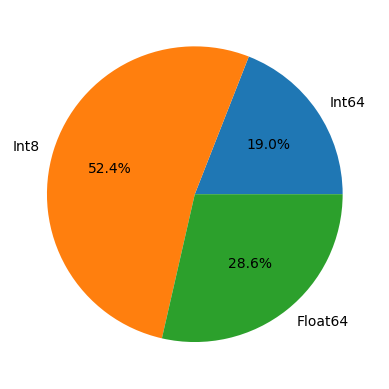

In [12]:
# Schéma des colonnes (nom + type)
pd.Series(Counter(df.schema.values())).plot.pie(autopct="%1.1f%%")

In [13]:
'''df.write_csv("mon_fichier.csv")'''

'df.write_csv("mon_fichier.csv")'

## 2. **Analyse univarié** 



## Variable quantitative

Une **variable quantitative** prend des valeurs numériques (ex. : âge, revenu, montant du panier).  
On distingue :
- les variables **continues** (peuvent prendre une infinité de valeurs dans un intervalle) ;
- les variables **discrètes** (valeurs entières, ex. nombre d’enfants).



Une **variable quantitative** est une variable numérique.  
Voici l’ensemble des analyses univariées possibles.

#  Analyse univariée des variables quantitatives  


Une variable quantitative peut être résumée selon plusieurs axes :  
**tendance centrale**, **dispersion**, **position**, **forme**, **visualisation**



| **Catégorie** | **Indicateurs / Outils** | **Description / Interprétation** |
|---------------|---------------------------|----------------------------------|
| **Tendance centrale** | **Moyenne** | Niveau moyen de la variable |
| | **Médiane** | Valeur centrale (50% en dessous, 50% au-dessus) |
| | **Mode** | Valeur la plus fréquente |
| **Dispersion** | **Variance** | Dispersion autour de la moyenne |
| | **Écart-type** | Variabilité typique (racine de la variance) |
| | **Étendue (Range)** | max − min |
| | **Coefficient de variation (CV)** | Variation relative : écart-type ÷ moyenne |
| **Position** | **Quartiles (Q1, Q2, Q3)** | Coupent la distribution en 4 parties |
| | **Quantiles (déciles, percentiles)** | Découpages plus fins de la distribution |
| | **IQR (Interquartile Range)** | Q3 − Q1, dispersion robuste |
| | **Bornes outliers** | Q1 − 1.5×IQR ; Q3 + 1.5×IQR |
| **Forme de la distribution** | **Skewness (asymétrie)** | >0 queue droite ; <0 queue gauche |
| | **Kurtosis (aplatissement)** | >0 pointue ; <0 plate ; ≈0 proche normale |
| **Visualisations** | **Histogramme** | Répartition par classes |
| | **KDE (densité)** | Courbe lissée de la distribution |
| | **Boxplot** | Quartiles + outliers |
| | **Violin plot** | Boxplot + densité |
| | **Line plot** | Évolution temporelle si données chronologiques |




À retenir  
Une analyse univariée quantitative répond à 5 questions clés :

1. **Quel est le niveau moyen ?** → moyenne, médiane  
2. **Quelle est la variabilité ?** → variance, écart-type, étendue  
3. **Comment se répartissent les observations ?** → quartiles, quantiles, IQR  
4. **Quelle est la forme de la distribution ?** → skewness, kurtosis  
5. **Comment visualiser efficacement ?** → histogramme, KDE, boxplot


In [14]:
numeric_df = (
    df
    .select(cs.numeric().exclude(pl.Int8))   # enlever les colonnes binaires
    .drop("patid", "total_pre_index_charge", "pre_asthma_charge")  # enlever par nom
)

numeric_df.head()

index_age,total_pre_index_cannisters_365,adherence,pre_asthma_days,pre_asthma_pharma_charge,log_charges,log_asthma_charge
i64,i64,f64,i64,f64,f64,f64
14,1,null,1,218.13,7.110506,5.385091
null,2,null,0,44.98,9.91791,3.806218
62,null,0.73842,null,99.26,7.994381,4.597743
null,2,0.084469,0,59.58,8.078288,null
40,1,0.506812,2,null,7.160267,3.394173


In [15]:
numeric_df.schema

Schema([('index_age', Int64),
        ('total_pre_index_cannisters_365', Int64),
        ('adherence', Float64),
        ('pre_asthma_days', Int64),
        ('pre_asthma_pharma_charge', Float64),
        ('log_charges', Float64),
        ('log_asthma_charge', Float64)])

In [16]:
numeric_df.select(
    pl.col(pl.Float64).null_count()
)

adherence,pre_asthma_pharma_charge,log_charges,log_asthma_charge
u32,u32,u32,u32
1863,1417,1429,1390


In [17]:
numeric_df.describe()

statistic,index_age,total_pre_index_cannisters_365,adherence,pre_asthma_days,pre_asthma_pharma_charge,log_charges,log_asthma_charge
str,f64,f64,f64,f64,f64,f64,f64
"""count""",13085.0,13131.0,12712.0,13124.0,13158.0,13146.0,13185.0
"""null_count""",1490.0,1444.0,1863.0,1451.0,1417.0,1429.0,1390.0
"""mean""",38.325793,0.794989,0.253408,1.428223,242.88367,7.982269,4.204495
"""std""",15.210683,0.723036,0.23014,2.46755,444.098457,1.645137,1.705917
"""min""",12.0,0.0,0.00545,0.0,1.0,0.0,0.0
"""25%""",26.0,0.0,0.084469,0.0,21.41,7.113337,3.063858
"""50%""",41.0,1.0,0.168937,1.0,46.16,8.047815,3.849722
"""75%""",51.0,1.0,0.337875,2.0,227.76,9.004609,5.43834
"""max""",65.0,2.0,1.0,71.0,5463.14,13.682976,8.605779



**Interprétation :**
- Si la moyenne et la médiane sont proches, la distribution est souvent relativement **symétrique**.
- Si la moyenne est nettement > médiane → asymétrie à droite (queue à droite).  
- Si la moyenne est nettement < médiane → asymétrie à gauche.


***Histogramme***

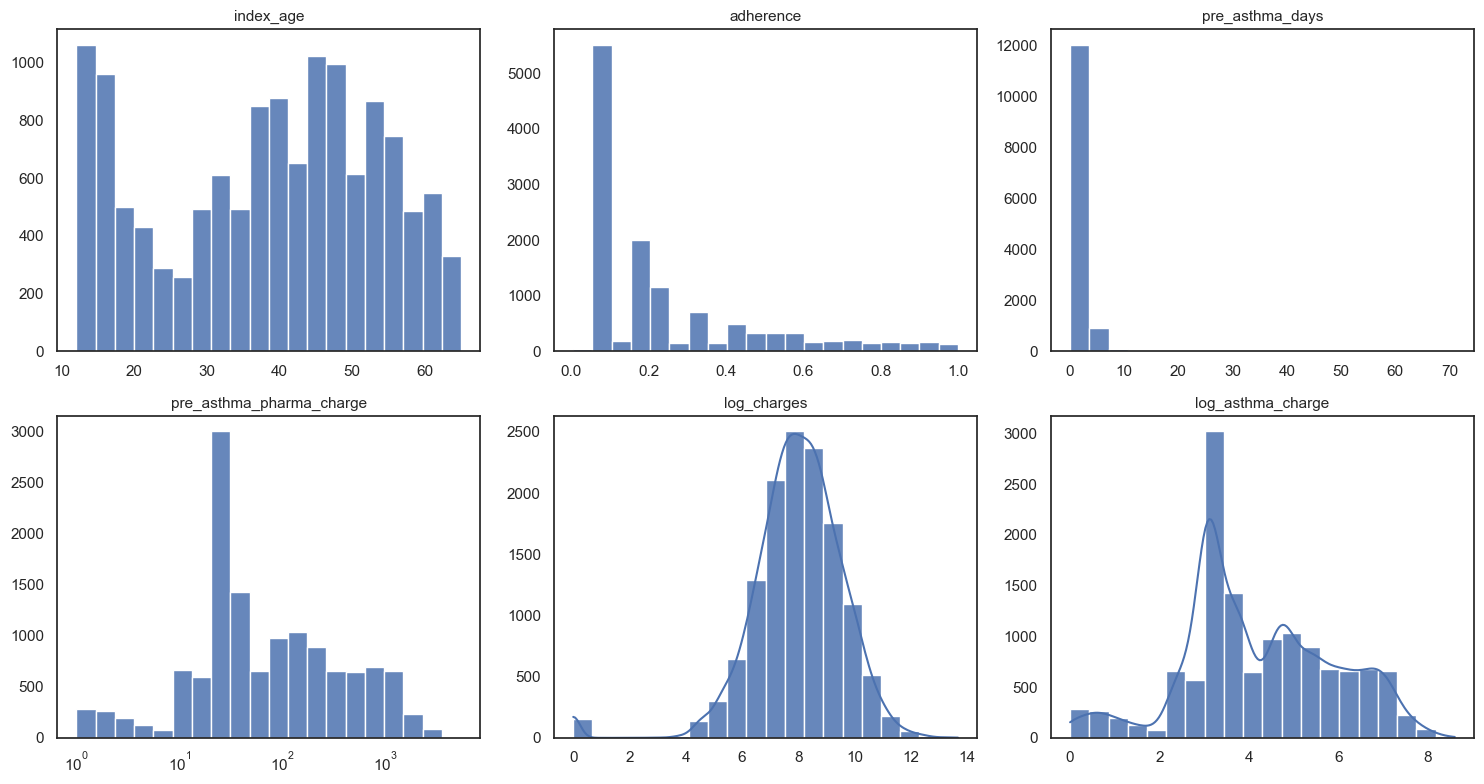

In [18]:
# variables à exclure
exclude = ["total_pre_index_cannisters_365"]

# garder seulement les variables continues
numeric_cols = [
    col for col in numeric_df.columns
    if col not in exclude
]

sns.set_style("white")
sns.set_context("notebook", font_scale=1)

n = len(numeric_cols)
rows = math.ceil(n / 3)

fig, axes = plt.subplots(rows, 3, figsize=(15, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):

    data = numeric_df.select(pl.col(col)).to_series().to_numpy()

    is_log = "log" in col
    is_charge_raw = ("charge" in col and not is_log)

    if is_charge_raw:
        data = data[data > 0]
        ax.set_xscale("log")

    sns.histplot(
        data,
        bins=20,
        kde=is_log,
        color="#4C72B0",
        alpha=0.85,
        ax=ax
    )

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[n:]:
    ax.remove()

plt.tight_layout()
plt.show()


**Forme de la distribution** : asymétrie et aplatissement

Deux indicateurs classiques :

- **Asymétrie (skewness)** : mesure la symétrie de la distribution.  
  - skewness ≈ 0 → distribution à peu près symétrique ;  
  - skewness > 0 → queue à droite ;  
  - skewness < 0 → queue à gauche.

- **Aplatissement (kurtosis)** : mesure la forme des queues de distribution.  
  - kurtosis ≈ 0 (en version « excess kurtosis ») → proche de la loi normale ;  
  - kurtosis > 0 → distribution plus « pointue », queues plus lourdes ;  
  - kurtosis < 0 → distribution plus « plate ».


***boxplot***

Quartiles, quantiles, IQR et outliers
Pour analyser la répartition d’une variable quantitative, on utilise des mesures de position : quartiles, quantiles, IQR et bornes d’outlier


| **Indicateur** | **Définition** | **Utilité** |
|---------------|----------------|--------------|
| **Quartiles (Q1, Q2, Q3)** | Découpent les données en 4 parties | Comprendre la position des valeurs |
| **Quantiles** | Découpent les données en k parties (déciles, percentiles) | Analyse plus fine des répartitions |
| **IQR** | \(Q_3 - Q_1\) | Mesure robuste de dispersion |
| **Bornes outliers** | \(Q_1 - 1.5×IQR\), \(Q_3 + 1.5×IQR\) | Détection des valeurs extrêmes |

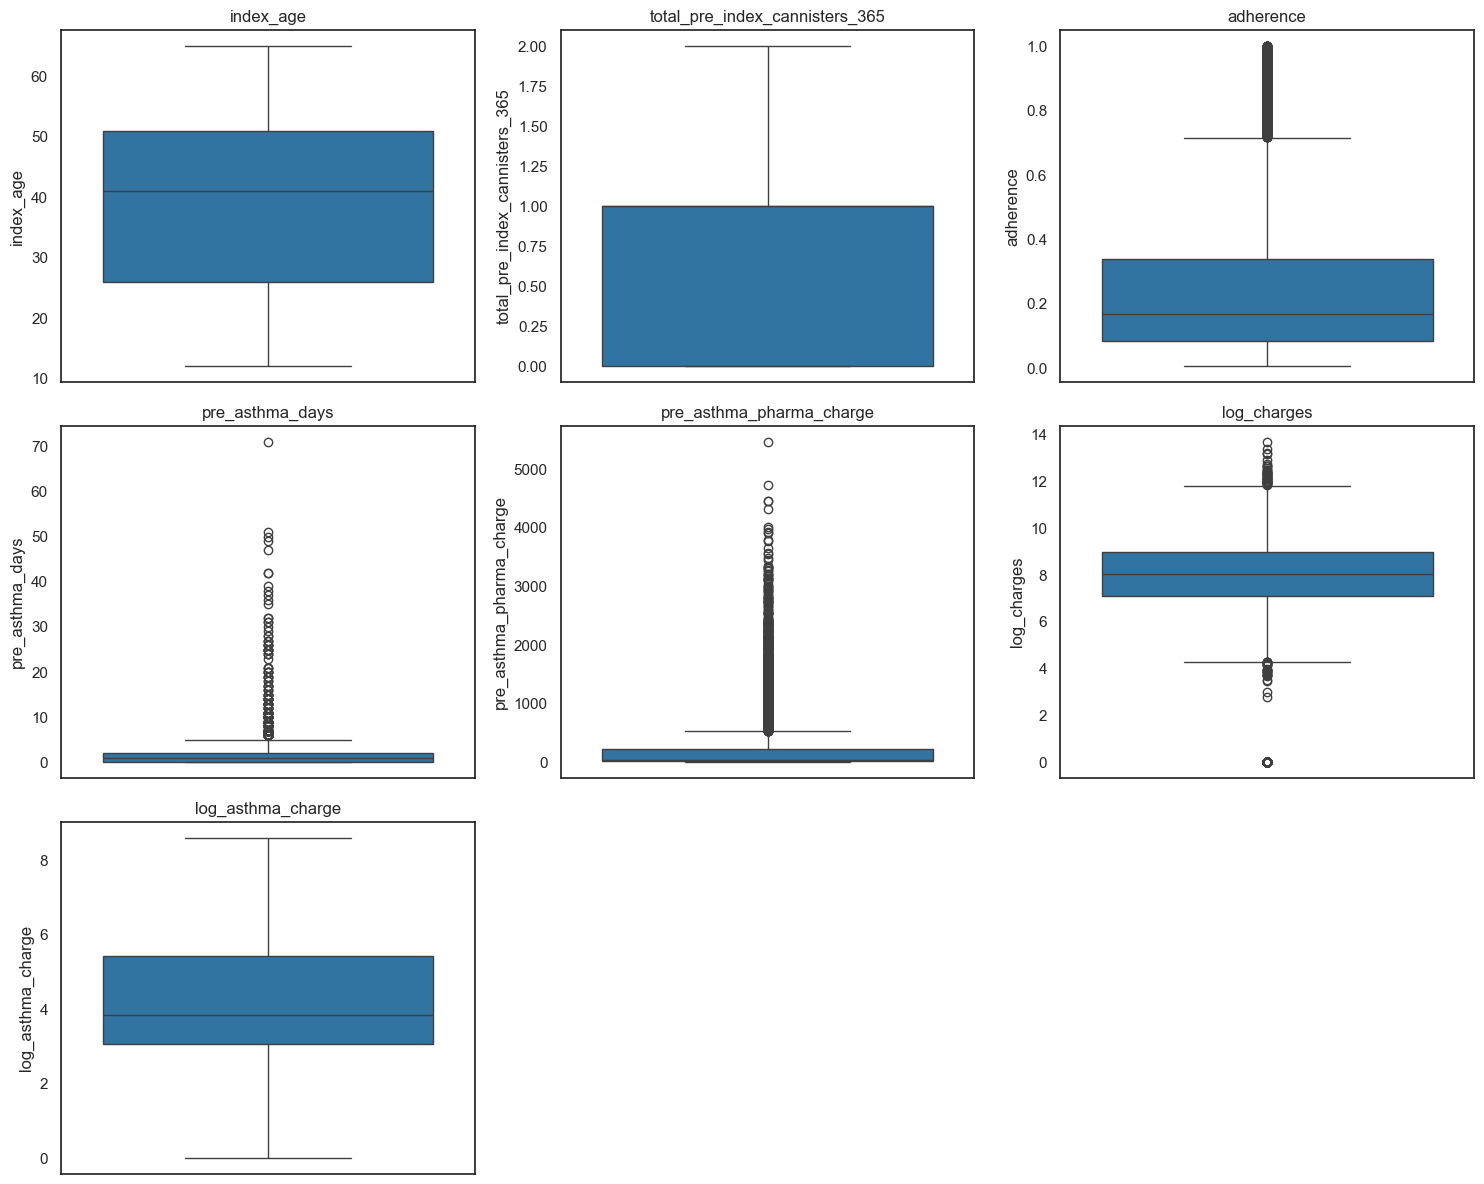

In [19]:
n = len(numeric_df.columns)
rows = math.ceil(n / 3)

fig, axes = plt.subplots(rows, 3, figsize=(15, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_df.columns):
    sns.boxplot(y=numeric_df[col], ax=ax)
    ax.set_title(col)

for ax in axes[n:]:
    ax.remove()

plt.tight_layout()
plt.show()

***countplot***

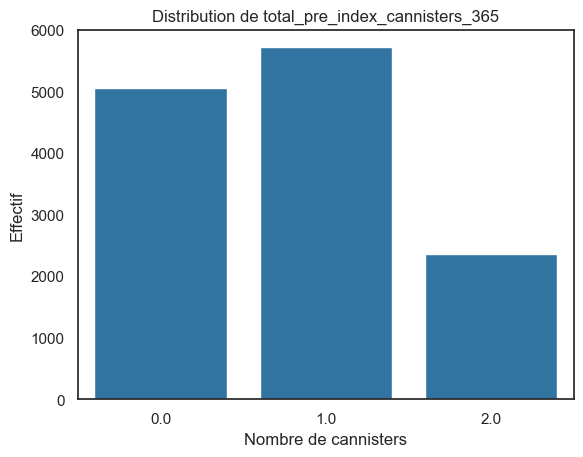

In [20]:
sns.countplot(
    data=numeric_df,
    x="total_pre_index_cannisters_365"
)

plt.title("Distribution de total_pre_index_cannisters_365")
plt.xlabel("Nombre de cannisters")
plt.ylabel("Effectif")
plt.show()

***table contingence***

In [21]:
(
    numeric_df
    .group_by("total_pre_index_cannisters_365")
    .len()
    .with_columns(
        (pl.col("len") / pl.sum("len")).alias("proportion")
    )
)

total_pre_index_cannisters_365,len,proportion
i64,u32,f64
null,1444,0.099074
2,2362,0.162058
0,5054,0.346758
1,5715,0.39211


Tests de normalité

Dans beaucoup de méthodes statistiques (tests paramétriques, régressions, etc.), on suppose qu’une variable suit **approximativement une loi normale**.

Il est donc utile de :
- **visualiser** la distribution ;
- utiliser des **tests de normalité** :
  - Shapiro–Wilk ;
  - Kolmogorov–Smirnov (KS) ;
- examiner un **Q-Q plot (quantile-quantile)**.


- H0 : la variable suit une distribution normale
- H1 : la variable ne suit pas une distribution normale

- si p-value < 0.05 → on rejette H0
- si p-value ≥ 0.05 → on ne rejette pas H0

- W ≈ 1  → distribution proche de la normale
- W plus petit → distribution s'éloigne de la normale

In [ ]:
from scipy.stats import shapiro

data = (
    numeric_df
    .select("log_charges")
    .drop_nulls()
    .to_numpy()
    .flatten()
)

stat, p = shapiro(data)

print("Statistic :", stat)
print("p-value :", p)

In [ ]:
stats.probplot(data, dist="norm", plot=plt)

plt.title("Q-Q plot : log_charges")
plt.show()

***outliers***

[Outlier](https://mrmint.fr/outliers-machine-learning)

IQR (outliers) - extrêmes robustes (quantiles)

In [27]:
iqr_mask  = None

for col in numeric_df.columns:

    q1 = numeric_df.select(pl.col(col).quantile(0.25)).item()
    q3 = numeric_df.select(pl.col(col).quantile(0.75)).item()
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    cond = (pl.col(col) < lower) | (pl.col(col) > upper)

    if iqr_mask  is None:
        iqr_mask  = cond
    else:
        iqr_mask  = iqr_mask  | cond

df_out_iqr = numeric_df.filter(iqr_mask )

iqr_summary = pl.DataFrame({
    "method": ["IQR"],
    "n_outliers": [df_out_iqr.height],
    "pct_outliers": [df_out_iqr.height / df.height * 100]
})

iqr_summary

method,n_outliers,pct_outliers
str,i64,f64
"""IQR""",1066,7.313894


**Variables qualitative**

Une **variable qualitative** décrit des catégories : sexe, produit, canal d'achat, etc.

On distingue :
- les variables **nominales** (sans ordre naturel : couleur, pays…)  
- les variables **ordinales** (avec ordre logique : faible/moyen/fort, notes 1–5…)

| **Catégorie** | **Indicateurs / Outils** | **Description / Interprétation** |
|---------------|---------------------------|----------------------------------|
| **Type de variable** | **Nominale** | Catégories sans ordre (ex : pays, produit, couleur) |
| | **Ordinale** | Catégories ordonnées (ex : niveau 1–5, faible/moyen/fort) |
| **Fréquences** | **Effectifs** | Nombre d’observations par modalité |
| | **Proportions (%)** | Fréquences relatives, interprétation intuitive |
| | **Fréquences cumulées** | Utile pour variables ordinales |
| **Mesures adaptées** | **Mode** | Modalité la plus fréquente |
| | **Diversité / richesse** | Nombre total de catégories distinctes |
| | **Indice de concentration** | Mesure si quelques catégories dominent |
| **Visualisations** | **Barplot (vertical)** | Comparaison des effectifs |
| | **Barplot horizontal** | Idéal si plus de 5 catégories |
| | **Pie chart** | Proportions (à utiliser avec prudence) |
| | **Countplot (seaborn)** | Version graphique automatique de value_counts() |
| | **Treemap** | Représentation visuelle de la répartition |


À retenir  
Une analyse univariée qualitative répond à 4 questions clés :

1. **Quel est le type de variable ?** → nominale ou ordinale  
2. **Comment se répartissent les catégories ?** → effectifs, proportions  
3. **Quelle catégorie domine ?** → mode, concentration  
4. **Comment visualiser efficacement ?** → barplot, countplot, treemap, pie chart (rarement)



In [36]:

cate_df = (
    df.with_columns(
        pl.when(pl.col("post_index_exacerbations365") > 0)
          .then(pl.lit(1))
          .otherwise(pl.lit(0))
          .cast(pl.Int8)
          .alias("post_index_exacerbations365")
    )
    .select(pl.col(pl.Int8))
)

cate_df.head()

previous_asthma_drugs,post_index_exacerbations365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,drug_s,female
i8,i8,i8,i8,i8,i8,i8,i8,i8,i8,i8
1,0,0,0,1,0,1,0,0,0,null
1,1,0,1,1,0,0,0,1,0,0
1,0,0,0,null,0,0,0,0,0,0
1,0,0,0,1,0,1,null,0,0,1
1,0,0,1,0,1,1,0,1,0,0


In [37]:
cate_df.columns

['previous_asthma_drugs',
 'post_index_exacerbations365',
 'pneumonia',
 'sinusitis',
 'acute_bronchitis',
 'acute_laryngitis',
 'upper_respiratory_infection',
 'gerd',
 'rhinitis',
 'drug_s',
 'female']


Effectifs et proportions

Pour décrire une variable qualitative, on regarde :
- les **effectifs** (nombre d'observations par modalité) ;
- les **proportions** ou **pourcentages**.


In [38]:
tables = {}

for col in cate_df.columns:

    table = (
        cate_df
        .group_by(col)
        .len()
        .rename({"len": "effectif"})
        .with_columns(
            (pl.col("effectif") / cate_df.height * 100).alias("proportion_%")
        )
        .sort("effectif", descending=True)
    )

    tables[col] = table

In [39]:
tables["post_index_exacerbations365"]

post_index_exacerbations365,effectif,proportion_%
i8,u32,f64
0,12913,88.596913
1,1662,11.403087


In [40]:
tables["female"]

female,effectif,proportion_%
i8,u32,f64
1,8338,57.207547
0,4828,33.125214
null,1409,9.667238


Pie chart

In [41]:
def pie_plot_from_tables(tables, col):

    df = tables[col]

    labels = df[col].fill_null("Missing").to_list()
    sizes = df["effectif"].to_list()

    plt.figure(figsize=(5,5))

    plt.pie(
        sizes,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title(f"Distribution de {col}")
    plt.show()

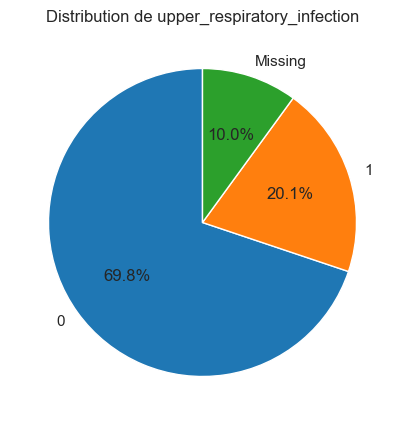

In [42]:
pie_plot_from_tables(tables, "upper_respiratory_infection")

Barplot

In [43]:
def barplot_from_tables(tables, col):

    df = tables[col]

    labels = df[col].fill_null("Missing").to_list()
    values = df["effectif"].to_list()

    plt.figure(figsize=(6,4))

    plt.bar(labels, values)

    plt.title(f"Distribution de {col}")
    plt.ylabel("Effectif")
    plt.xlabel(col)

    plt.show()

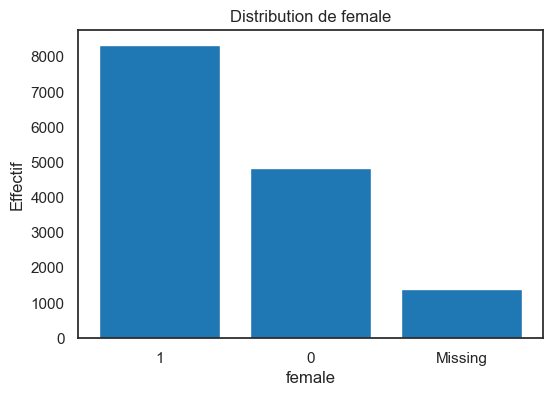

In [44]:
barplot_from_tables(tables, "female")

Treemap

In [45]:
import matplotlib.pyplot as plt
import squarify


def treemap_from_tables(tables, col):

    df = tables[col]

    labels = df[col].fill_null("Missing").to_list()
    sizes = df["effectif"].to_list()

    labels = [f"{l}\n{v}" for l, v in zip(labels, sizes)]

    plt.figure(figsize=(6,4))

    squarify.plot(
        sizes=sizes,
        label=labels,
        alpha=0.8
    )

    plt.title(f"Treemap - {col}")
    plt.axis("off")

    plt.show()

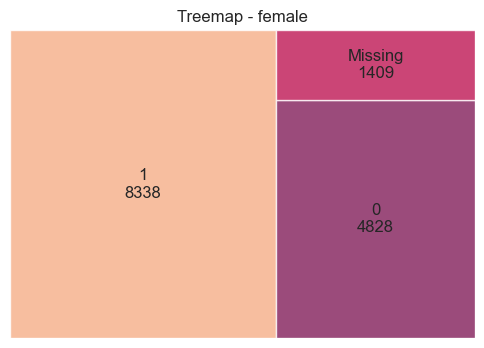

In [46]:
treemap_from_tables(tables, "female")

**Analyse bivarié**

Target / Age 

In [ ]:
target=cate_df.select("post_index_exacerbations365")

In [ ]:
df_age_exac = (
    numeric_df
    .select("index_age")
    .with_columns(
        target["post_index_exacerbations365"]
    )
)

sns.boxplot(
    x="post_index_exacerbations365",
    y="index_age",
    data=df_age_exac
)

plt.show()

In [ ]:
df_age_exac = (
    df_age_exac
    .with_columns(
        pl.when(pl.col("index_age") < 20).then(pl.lit("10-19"))
        .when(pl.col("index_age") < 30).then(pl.lit("20-29"))
        .when(pl.col("index_age") < 40).then(pl.lit("30-39"))
        .when(pl.col("index_age") < 50).then(pl.lit("40-49"))
        .when(pl.col("index_age") < 60).then(pl.lit("50-59"))
        .otherwise(pl.lit("60-69"))
        .alias("age_group")
    )
    .select(["age_group", "post_index_exacerbations365"])
    .to_pandas()
)

plt.figure(figsize=(8,5))

sns.countplot(
    data=df_age_exac,
    x="age_group",
    hue="post_index_exacerbations365"
)

plt.title("Exacerbations selon tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Nombre de patients")
plt.show()

Target / Sexe 

In [ ]:
df_sexe_exac = (
    cate_df
    .select("female")
    .with_columns(
        target["post_index_exacerbations365"]
    )
)
crosstab_percent = (
    df_sexe_exac
    .group_by(["female", "post_index_exacerbations365"])
    .agg(pl.len().alias("count"))
    .with_columns(
        (pl.col("count") / pl.sum("count").over("female") * 100)
        .alias("percent")
    )
    .pivot(
        values="percent",
        index="female",
        columns="post_index_exacerbations365"
    )
    .sort("female")
)

crosstab_percent

Les femmes présentent un taux d’exacerbation legerement plus élevé que les hommes.

In [ ]:
df_plot = (
    df_sexe_exac
    .to_pandas()
)

ct = pd.crosstab(
    df_plot["female"],
    df_plot["post_index_exacerbations365"],
    normalize="index"
) * 100

ct.plot(kind="bar", stacked=True)

plt.ylabel("Pourcentage (%)")
plt.title("Exacerbations par sexe")
plt.show()

Target / Comorbidité 

Barplot

In [ ]:
comorbidites = [
    "pneumonia",
    "sinusitis",
    "acute_bronchitis",
    "acute_laryngitis",
    "upper_respiratory_infection",
    "gerd",
    "rhinitis",
]

In [ ]:
df_comorbidite_exac = (
    cate_df
    .select(comorbidites)
    .with_columns(
        target["post_index_exacerbations365"]
    )
)

In [ ]:
prop_0_list = []
prop_1_list = []

for var in comorbidites:
    
    table = (
        df_comorbidite_exac
        .group_by([var, "post_index_exacerbations365"])
        .agg(pl.count().alias("n"))
        .pivot(
            values="n",
            index=var,
            columns="post_index_exacerbations365"
        )
        .sort(var)
    )
    
    # Ligne où comorbidité = 1
    row = table.filter(pl.col(var) == 1)
    
    if row.height == 0:
        prop_0, prop_1 = 0, 0
    else:
        count_0 = row["0"][0] if "0" in row.columns else 0
        count_1 = row["1"][0] if "1" in row.columns else 0
        total = count_0 + count_1
        
        prop_0 = count_0 / total if total > 0 else 0
        prop_1 = count_1 / total if total > 0 else 0
    
    prop_0_list.append(prop_0)
    prop_1_list.append(prop_1)

x = np.arange(len(comorbidites))

plt.figure(figsize=(12,6))

bars0 = plt.bar(x, prop_0_list, label="Pas d'exacerbation")
bars1 = plt.bar(x, prop_1_list, bottom=prop_0_list, label="exacerbation")

# Ajouter % dans les barres
for i in range(len(x)):
    plt.text(i, prop_0_list[i]/2,
             f"{prop_0_list[i]*100:.1f}%",
             ha="center", color="white", fontsize=8)
    
    plt.text(i,
             prop_0_list[i] + prop_1_list[i]/2,
             f"{prop_1_list[i]*100:.1f}%",
             ha="center", color="white", fontsize=8)

plt.xticks(x, comorbidites, rotation=45)
plt.ylabel("Proportion")
plt.title("Pourcentage Target selon chaque comorbidité ")
plt.legend()
plt.tight_layout()
plt.show()

Aucune comorbidité ne montre une différence visuellement très marquée par rapport aux autres.

Table de contingence 

In [ ]:
for var in comorbidites:
    print(f"\nAnalyse complète : {var}")
    
    result = (
        df
        .group_by(var)
        .agg([
            pl.count().alias("n"),
            pl.col("post_index_exacerbations365").sum().alias("n_exacerbations"),
            pl.col("post_index_exacerbations365").mean().alias("proportion")
        ])
        .sort(var)
    )
    
    print(result)

'''***Test du Chi²***
> Question à laquelle il répond :Y a-t-il une association statistique entre la variable et la Target ?

Il donne :
- une p-value
- significatif ou pas
- Mais il ne donne PAS l’intensité de l’effet.

***Odds Ratio (OR)***
> Question : Quelle est l’ampleur de l’effet ?
- OR = 1.37 → effet modéré
- OR ≈ 1 → négligeable
- OR > 2 → fort

***Régression logistique***
> Question : L’effet tient-il quand on contrôle d’autres variables ?

- C’est la version multivariée.
- C’est la plus rigoureuse scientifiquement.'''

**Target / Variables de coûts**

In [ ]:
cost_vars = [
    "pre_asthma_pharma_charge",
    "log_charges",
    "log_asthma_charge",

]

In [ ]:
df_plot = (
    numeric_df
    .select(cost_vars)
    .with_columns(
        target["post_index_exacerbations365"]
    )
)

In [ ]:
n = len(cost_vars)
rows = math.ceil(n / 3)

fig, axes = plt.subplots(rows, 3, figsize=(15, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, cost_vars):
    sns.boxplot(
        data=df_plot,
        x="post_index_exacerbations365",
        y=col,
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("Exacerbation")
    ax.set_ylabel("")

for ax in axes[n:]:
    ax.remove()

plt.tight_layout()
plt.show()

In [ ]:
sns.set_style("white")
sns.set_context("notebook", font_scale=1)

n = len(cost_vars)
rows = math.ceil(n / 2)

fig, axes = plt.subplots(rows, 2, figsize=(12, 4 * rows))
axes = axes.flatten()

raw_charge_vars = [
    "pre_asthma_charge",
    "pre_asthma_pharma_charge",
    "total_pre_index_charge"
]

for ax, col in zip(axes, cost_vars):

    is_log = "log" in col
    is_raw = col in raw_charge_vars

    sns.histplot(
        data=df_plot,
        x=col,
        hue="post_index_exacerbations365",
        bins=25,
        stat="density",
        common_norm=False,
        element="step",
        kde=is_log,
        palette=["#4C72B0", "#DD8452"],
        ax=ax
    )

    # Échelle log pour charges brutes
    if is_raw:
        ax.set_xscale("log")
        ax.set_xlim(left=1)

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Density")

# supprimer axes inutilisés
for ax in axes[n:]:
    ax.remove()

plt.tight_layout()
plt.show()

Il n’y a PAS de séparation franche.
Les distributions se chevauchent beaucoup.

**Target / Intensité de la prise en charge et utilisation des traitements**

In [ ]:
vars_tt = [
    "total_pre_index_cannisters_365",
    "pre_asthma_days"
]

df_plot = (
    numeric_df
    .select(vars_tt)
    .with_columns(
        target["post_index_exacerbations365"]
    )
)

In [ ]:
n = len(vars_tt)
rows = math.ceil(n / 2)

fig, axes = plt.subplots(rows, 2, figsize=(12, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, vars_tt):
    
    sns.boxplot(
        data=df_plot,
        x="post_index_exacerbations365",
        y=col,
        ax=ax
    )
    
    ax.set_title(col)
    ax.set_xlabel("Target")
    ax.set_ylabel("")

for ax in axes[n:]:
    ax.remove()

plt.tight_layout()
plt.show()

- les boîtes se superposent presque entièrement. La consommation annuelle de SABA ne distingue pas clairement les patients qui auront une exacerbation de ceux qui n’en auront pas.
- Le nombre de jours de traitement pré-index est également très similaire entre exacerbation et non-exacerbation , concentrée sur les faibles valeurs (proche de 0–2)jours . Le groupe sans exacerbation (0) montre des valeurs extrêmes plus élevées que le groupe avec exacerbation (1).

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df_plot,
    x="total_pre_index_cannisters_365",
    hue="post_index_exacerbations365"
)

plt.title("Nombre de canisters selon Target")
plt.xlabel("total_pre_index_cannisters_365")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

- La majorité des patients ont 0 ou 1 bonbonne. 1 bonbonne semble associée à la proportion la plus élevée. La distribution est tronquée (limitée par les critères de sélection), ce qui restreint l’amplitude observable

In [ ]:
df_plot_pd = df_plot.to_pandas()

df_plot_pd["days_cat"] = pd.cut(
    df_plot_pd["pre_asthma_days"],
    bins=[-1, 0, 5, 10, 20, 100],
    labels=["0", "1-5", "6-10", "11-20", ">20"]
)

plt.figure(figsize=(8,4))

sns.countplot(
    data=df_plot_pd,
    x="days_cat",
    hue="post_index_exacerbations365"
)

plt.title("Pré-asthma days selon Target")
plt.xlabel("Catégorie de jours")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

- La majorité des patients ont 0 ou 1–5 jours de traitement. Les catégories au-delà de 5 jours sont très rares. Il n’y a pas de progression nette et continue de la part d’exacerbations avec l’augmentation du nombre de jours.

In [ ]:
numeric_df.schema

### Analyse approfondie 

Cout et cout 

In [ ]:
couts=["pre_asthma_pharma_charge","log_charges","log_asthma_charge"]
numeric_df_couts=numeric_df.select(couts)
numeric_df_couts = numeric_df_couts.to_pandas()
sns.clustermap(
    numeric_df_couts.corr(),
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.show()

Cout et Age

In [ ]:
couts_age=['index_age',"pre_asthma_pharma_charge","log_charges","log_asthma_charge"]
df_cout_age = (
    numeric_df
    .select(couts_age)
    .with_columns(
        target["post_index_exacerbations365"]
    )
)
df_cout_age = df_cout_age.to_pandas()

In [ ]:
for col in couts_age : 
    sns.lmplot(
        data=df_cout_age,
        x="index_age",
        y=col,
        hue="post_index_exacerbations365"
    )

    plt.title("Relation âge et couts selon la classe")
    plt.show()

In [ ]:
df_cout_age.corr()["index_age"].sort_values()

In [ ]:
df_cout_age.cov()["index_age"].sort_values()

In [ ]:
sns.lmplot(
    data=df.select([
        "pre_asthma_days",
        "log_asthma_charge"
    ]).to_pandas(),
    x="pre_asthma_days",
    y="log_asthma_charge",
    scatter_kws={"alpha":0.3}
)
plt.title("Relation jours de traitement et coût asthme (log)")
plt.show()

Plus un patient a de jours de traitement asthme, plus le coût associé est élevé.

In [ ]:
sns.lmplot(
    data=df.select([
        "adherence",
        "log_asthma_charge"
    ]).to_pandas(),
    x="adherence",
    y="log_asthma_charge",
    scatter_kws={"alpha":0.3}
)
plt.show()

In [ ]:
sns.boxplot(
    data=df.select([
        "total_pre_index_cannisters_365",
        "log_charges"
    ]).to_pandas(),
    x="total_pre_index_cannisters_365",
    y="log_charges"
)
plt.show()